<a href="https://colab.research.google.com/github/contre55/ie332-project-group-/blob/main/A2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AI
I have used ChatGPT to check how to sort the zones alphabetically in part b of Question 1 and how to turn the grouped index "zone" back into a regular column in part a of Question 2; reset_index(). I also used AI to help me get rid of "zone" word column in Q1 part b by using drop, so that way there are no issues with converting the string to numbers later on.



# Part A

In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

if not Path("nba_shots.csv").is_file():
    raise FileNotFoundError("Upload nba_shots.csv to Colab's Files panel, then rerun this cell.")

shots = pd.read_csv("nba_shots.csv")

print("Dataset shape:", shots.shape)
display(shots.head())

Dataset shape: (20000, 11)


,shot_id,player,period,shot_clock,dist_ft,defender_ft,zone,catch_and_shoot,is_home,points,made
0,1,Vince Okafor,1,14.1,28.6,8.1,abovebreak3,0,1,3,1
1,2,Drew Hollis,4,13.2,29.7,3.0,abovebreak3,0,0,0,0
2,3,Jamal Price,3,12.5,3.1,6.2,restricted,0,0,2,1
3,4,Rex Dunn,2,14.4,25.6,6.5,abovebreak3,1,0,3,1
4,5,Devon Reyes,3,14.5,23.6,2.2,corner3,1,1,3,1


# Question 1
a.

The goal is to predict whether the player will score according to factors like the zone they shoot from, their distance to the basket, and their distance to the nearest opposing player. Because the model is predicting whether the player will make or miss, this is a binary choice, hence this is a classification problem.

Using "points" as an input is not appropriate as it results in data leakage because "points" data are recorded after the shot so they reveal the outcome. This means that the model does not actually learn how to predict and just looks up the answer that it is already fed, which results in a very high validation score that is misleading and inaccurate.

b.

In [ ]:
# Distance only table
X_distance = shots[["dist_ft"]].copy()

# Full features
full_features = ["dist_ft", "defender_ft", "shot_clock", "period", "catch_and_shoot", "is_home", "zone"]

# One-hot zone encoding
X_zone = pd.get_dummies(shots["zone"], prefix="zone", dtype=int)

# Aphabetical order
X_full = pd.concat([shots[full_features].drop(columns="zone"), X_zone.sort_index(axis=1)], axis=1)

y = shots["made"]

print("Distance-only feature table")
print("Shape:", X_distance.shape)
print("Columns:", X_distance.columns.tolist())
display(X_distance)

print("\nFull feature table")
print("Shape:", X_full.shape)
print("Columns:", X_full.columns.tolist())
display(X_full)

print("\nTarget")
display(y)


Distance-only feature table
Shape: (20000, 1)
Columns: ['dist_ft']


,dist_ft
0,28.6
1,29.7
2,3.1
3,25.6
4,23.6
...,...
19995,2.9
19996,1.7
19997,3.2
19998,18.0



Full feature table
Shape: (20000, 11)
Columns: ['dist_ft', 'defender_ft', 'shot_clock', 'period', 'catch_and_shoot', 'is_home', 'zone_abovebreak3', 'zone_corner3', 'zone_midrange', 'zone_paint', 'zone_restricted']


,dist_ft,defender_ft,shot_clock,period,catch_and_shoot,is_home,zone_abovebreak3,zone_corner3,zone_midrange,zone_paint,zone_restricted
0,28.6,8.1,14.1,1,0,1,1,0,0,0,0
1,29.7,3.0,13.2,4,0,0,1,0,0,0,0
2,3.1,6.2,12.5,3,0,0,0,0,0,0,1
3,25.6,6.5,14.4,2,1,0,1,0,0,0,0
4,23.6,2.2,14.5,3,1,1,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
19995,2.9,3.6,7.6,3,0,1,0,0,0,0,1
19996,1.7,6.0,6.6,1,1,1,0,0,0,0,1
19997,3.2,2.0,10.7,2,0,0,0,0,0,0,1
19998,18.0,4.8,12.2,4,0,0,0,0,1,0,0



Target


,made
0,1
1,0
2,1
3,1
4,1
...,...
19995,1
19996,1
19997,1
19998,0


For the distance only feature table, each row shows one shot, and the column "dist_ft" shows the corresponding distance of the shooter from the basket in feet. For the full table, similarly, each row shows one shot, and the columns show the "circumstances" of that shot: the column "dist_ft" shows the corresponding distance of the shooter from the basket in feet; "defender_ft" shows the distance from the shooter to the nearest opposing player in feet; and "is_home" shows whether the shooter's team is playing at its own or at the opponent's venue. The full second table shows more information about each shot and contains the six non-zone predictors and five one-hot encoded zone indicators. Each zone indicator is 1 if a shot belongs to that zone and 0 otherwise. All five zone categories are retained, and the zone columns are arranged in alphabetical order after the numeric predictors. The target y is made, which indicates whether each shot was successful.

c.

In [ ]:

train, test = train_test_split(shots, test_size=0.25, random_state=332)

# Distance only table
X_dist_train, y_dist_train = X_distance.loc[train.index], train["made"]
X_dist_test, y_dist_test = X_distance.loc[test.index], test["made"]

# Full table
X_full_train, y_full_train = X_full.loc[train.index], train["made"]
X_full_test, y_full_test = X_full.loc[test.index], test["made"]

print("Distance only table rows (training, test):", len(X_dist_train), len(X_dist_test))
print("Shape:", X_dist_train.shape)
print("Columns:", X_dist_train.columns.tolist())

print("\nFull table rows (training, test):", len(X_full_train), len(X_full_test))
print("Shape:", X_full_train.shape)
print("Columns:", X_full_train.columns.tolist())

Distance only table rows (training, test): 15000 5000
Shape: (15000, 1)
Columns: ['dist_ft']

Full table rows (training, test): 15000 5000
Shape: (15000, 11)
Columns: ['dist_ft', 'defender_ft', 'shot_clock', 'period', 'catch_and_shoot', 'is_home', 'zone_abovebreak3', 'zone_corner3', 'zone_midrange', 'zone_paint', 'zone_restricted']


# Question 2

a

,zone,n_shots,make_rate
4,restricted,4476,0.673369
3,paint,3185,0.525903
1,corner3,1502,0.421438
2,midrange,2569,0.382639
0,abovebreak3,3268,0.337515


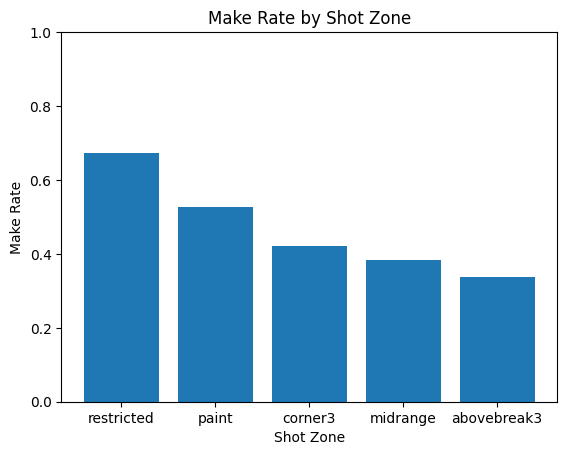

In [ ]:
zone_summary = train.groupby("zone").agg(
    n_shots=("made", "count"),
    make_rate=("made", "mean")
).reset_index()

zone_summary = zone_summary.sort_values("make_rate", ascending=False)
display(zone_summary)

# Graphing
plt.bar(zone_summary["zone"], zone_summary["make_rate"])
plt.xlabel("Shot Zone")
plt.ylabel("Make Rate")
plt.title("Make Rate by Shot Zone")
plt.ylim(0, 1)
plt.show()

b

In [ ]:
three_point_shots = train[train["zone"].isin(["corner3", "abovebreak3"])].copy()
three_point_shots["open_shot"] = three_point_shots["defender_ft"] >= 6
open_summary = three_point_shots.groupby("open_shot").agg(
    n_shots=("made", "count"),
    make_rate=("made", "mean")
).reset_index()

display(open_summary)


,open_shot,n_shots,make_rate
0,False,3725,0.320000
1,True,1045,0.520574


**PART C**

Question 5a

In [ ]:
from matplotlib import cm
from sklearn.metrics import accuracy_score, confusion_matrix

tree_q5 = DecisionTreeClassifier(
    max_depth=4,
    min_samples_leaf=50,
    random_state=332
)
tree_q5.fit(X_full_train, y_full_train)

y_pred_q5 = tree_q5.predict(X_full_test)

accuracy_q5 = accuracy_score(y_full_test, y_pred_q5)
print("Test Accuracy:", round(accuracy_q5, 3))

cm_q5 = confusion_matrix(y_full_test, y_pred_q5, labels=[0,1])

cm_df_q5 = pd.DataFrame(cm_q5,
    index=["Actual Miss (0)", "Actual Make(1)"],
    columns=["Predicted Miss (0)", "Predicted Make (1)"]
)

display(cm_df_q5)

Test Accuracy: 0.633


,Predicted Miss (0),Predicted Make (1)
Actual Miss (0),1794,736
Actual Make(1),1098,1372


Question 5b

In [ ]:
TN, FP, FN, TP = cm_q5.ravel()

precision = TP / (TP + FP)
recall = TP / (TP + FN)

print("Precision calculations:", TP, "/", TP + FP)
print("Precision:", round(precision,3))

print("Recall calculation:", TP, "/", TP + FN)
print("Recall:", round(recall,3))

Precision calculations: 1372 / 2108
Precision: 0.651
Recall calculation: 1372 / 2470
Recall: 0.555


Question 6a

In [ ]:
TN = 598
FP = 53
FN = 207
TP = 46

total_attempts = TN + FP + FN + TP
actual_makes = FN + TP
actual_misses = TN + FP

print("Total attempts:", total_attempts)
print("Actual makes:", actual_makes)
print("Actual misses:", actual_misses)

model_accuracy = (TP + TN) / total_attempts
model_recall = TP / actual_makes

miss_accuracy = actual_misses / total_attempts
miss_recall = 0 / actual_makes

comparison = pd.DataFrame({
    "method" : ["Original Model", "Always Predict Miss"],
    "accuracy": [model_accuracy, miss_accuracy],
    "recall" : [model_recall, miss_recall]
})

display(comparison.round(3))

print("Model Accuracy:", TP + TN, "/", total_attempts)
print("Model Recall:", TP, "/", actual_makes)
print("Always miss accuracy:", actual_misses, "/", total_attempts)
print("Always miss recall:", 0, "/", actual_makes)

Total attempts: 904
Actual makes: 253
Actual misses: 651


,method,accuracy,recall
0,Original Model,0.712,0.182
1,Always Predict Miss,0.720,0.000


Model Accuracy: 644 / 904
Model Recall: 46 / 253
Always miss accuracy: 651 / 904
Always miss recall: 0 / 253


Question 6b

I do not agree. Even though prediciting a miss has a higher accuracy (0.72 vs 0.712), it has a recall of 0, which means it fails to identify any of the 253 actual makes. The original model has a recall of 0.182, correctly identifying 46/253 makes. Since there are more misses (651) than makes (253), always predicting a miss can achieve higher accuracy without identifying any made shots. So, a higher accuracy does not necessarily mean a model is better at identifying actual makes.